# AgroPredict Colombia
## Análisis Exploratorio de Datos (EDA)

**Fuente:** Evaluaciones Agropecuarias Municipales (EVA) - UPRA  
**Periodo:** 2019–2025  
**Cultivo:** Maíz  
**Unidad de análisis propuesta:** Municipio, año, periodo y desagregación del cultivo.

### Objetivo

Explorar la estructura, calidad, distribución y comportamiento temporal y territorial de los datos agrícolas del maíz en Colombia, identificando patrones y limitaciones relevantes para el desarrollo de un modelo predictivo del rendimiento agrícola (t/ha).

## 1. Carga y preparación de los datos

Se utiliza la base agrícola EVA 2019–2025 de la UPRA. Se identifican los encabezados reales del archivo y se seleccionan los registros correspondientes al cultivo de maíz.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración de visualizaciones
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

# Ruta relativa desde la carpeta notebooks
ruta = "../data/raw/20260526_BaseAgricola20192025.xlsx"

# Cargar la base con los encabezados correctos
df = pd.read_excel(
    ruta,
    sheet_name="BasePagina",
    header=8
)

# Seleccionar registros de maíz
maiz = df[df["Cultivo"] == "Maíz"].copy()

print(f"Registros totales: {len(df):,}")
print(f"Registros de maíz: {len(maiz):,}")
print(f"Variables disponibles: {maiz.shape[1]}")
print(f"Municipios representados: {maiz['Código Dane municipio'].nunique():,}")

display(maiz.head())

Registros totales: 166,733
Registros de maíz: 21,992
Variables disponibles: 18
Municipios representados: 1,050


,Código Dane departamento,Departamento,Código Dane municipio,Municipio,Desagregación cultivo,Cultivo,Ciclo del cultivo,Grupo cultivo,Subgrupo,Año,Periodo,Área sembrada (ha),Área cosechada (ha),Producción (t),Rendimiento (t/ha),Nombre científico del cultivo,Código del cultivo,Estado físico del cultivo
379,5,Antioquia,5002,Abejorral,Maíz amarillo tradicional,Maíz,Transitorio,Cereales,Cereales,2021,2021A,51.0,49.0,98.0,2.0,Zea mays,1010402,Grano seco
380,5,Antioquia,5002,Abejorral,Maíz amarillo tradicional,Maíz,Transitorio,Cereales,Cereales,2021,2021B,40.0,35.0,70.0,2.0,Zea mays,1010402,Grano seco
381,5,Antioquia,5002,Abejorral,Maíz amarillo tradicional,Maíz,Transitorio,Cereales,Cereales,2022,2022A,40.0,40.0,80.0,2.0,Zea mays,1010402,Grano seco
382,5,Antioquia,5002,Abejorral,Maíz amarillo tradicional,Maíz,Transitorio,Cereales,Cereales,2022,2022B,35.0,35.0,70.0,2.0,Zea mays,1010402,Grano seco
383,5,Antioquia,5002,Abejorral,Maíz amarillo tradicional,Maíz,Transitorio,Cereales,Cereales,2023,2023A,40.0,35.0,70.0,2.0,Zea mays,1010402,Grano seco


Se hace una exploración preliminar de los campos de dataframe para describir:
* Tipo
* Cantidad nulos
* Determinación si es o no una constante
* Pequeño resumen

In [11]:
def perfil_variables(data):
    filas = []
    for col in data.columns:
        s = data[col]
        no_numericas = ["Código Dane departamento", "Código Dane municipio", "Código del cultivo", "Año"]
        num = pd.api.types.is_numeric_dtype(s) and col not in no_numericas
        filas.append({
            "Variable": col,
            "Tipo": "Numérica" if num else "Categórica/ID",
            "Nulos": s.isna().sum(),
            "Únicos": s.nunique(),
            "Constante": s.nunique() == 1,
            "Resumen": (f"min {s.min():.0f} | mediana {s.median():.0f} | max {s.max():.0f}"
                        if num else
                        ", ".join(map(str, s.value_counts().index[:5])) + ("..." if s.nunique() > 5 else ""))
        })
    return pd.DataFrame(filas)

display(perfil_variables(maiz))

,Variable,Tipo,Nulos,Únicos,Constante,Resumen
0,Código Dane departamento,Categórica/ID,0,32,False,"25, 5, 68, 41, 15..."
1,Departamento,Categórica/ID,0,32,False,"Cundinamarca, Antioquia, Santander, Huila, Boyacá..."
2,Código Dane municipio,Categórica/ID,0,1050,False,"13654, 17042, 19532, 20011, 20295..."
3,Municipio,Categórica/ID,0,972,False,"La Unión, Bolívar, Granada, San Pedro, Guadalupe..."
4,Desagregación cultivo,Categórica/ID,0,6,False,"Maíz amarillo tradicional, Maíz blanco tradicional, Maíz tradicional, Maíz amarillo tecnificado, Maíz blanco tecnificado..."
5,Cultivo,Categórica/ID,0,1,True,Maíz
6,Ciclo del cultivo,Categórica/ID,0,1,True,Transitorio
7,Grupo cultivo,Categórica/ID,0,1,True,Cereales
8,Subgrupo,Categórica/ID,0,1,True,Cereales
9,Año,Categórica/ID,0,7,False,"2022, 2023, 2021, 2024, 2025..."


## 2. Análisis de la variable objetivo: rendimiento agrícola

Se examina la distribución del rendimiento del maíz (t/ha), identificando medidas de tendencia central, dispersión y posibles valores extremos.

Los registros con rendimiento igual a cero se conservan inicialmente para evaluar su comportamiento antes de definir criterios de tratamiento.

Estadísticas del rendimiento (t/ha):


count    21992.00
mean         2.19
std          1.76
min          0.00
25%          1.12
50%          1.60
75%          3.00
max         28.00
Name: Rendimiento (t/ha), dtype: float64

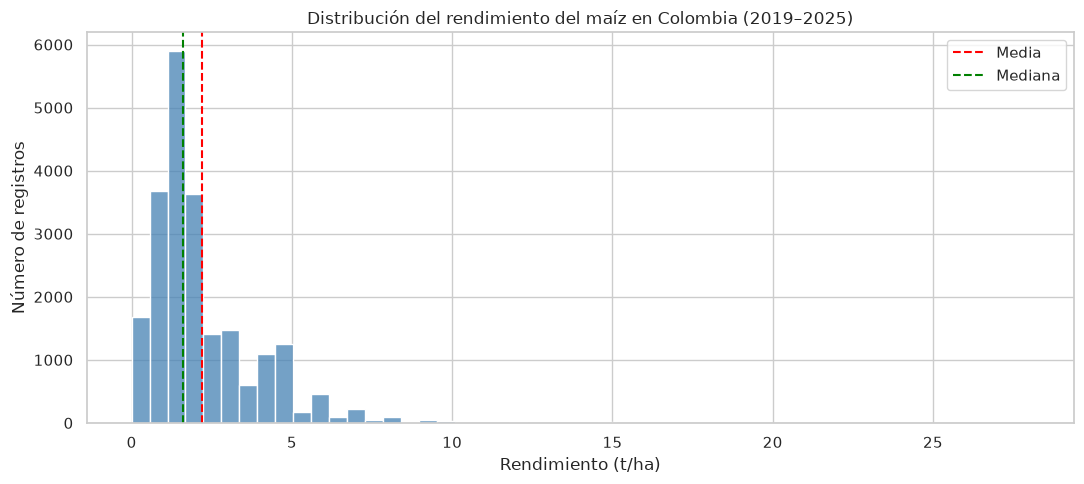

In [4]:
# Estadísticas descriptivas del rendimiento
print("Estadísticas del rendimiento (t/ha):")
display(maiz["Rendimiento (t/ha)"].describe().round(2))

# Histograma
plt.figure(figsize=(11, 5))

sns.histplot(
    data=maiz,
    x="Rendimiento (t/ha)",
    bins=50,
    color="steelblue",
    edgecolor="white"
)

plt.axvline(
    maiz["Rendimiento (t/ha)"].mean(),
    color="red",
    linestyle="--",
    label="Media"
)

plt.axvline(
    maiz["Rendimiento (t/ha)"].median(),
    color="green",
    linestyle="--",
    label="Mediana"
)

plt.title("Distribución del rendimiento del maíz en Colombia (2019–2025)")
plt.xlabel("Rendimiento (t/ha)")
plt.ylabel("Número de registros")
plt.legend()
plt.tight_layout()
plt.show()

## 3. Comparación del rendimiento por sistema productivo

Se compara el rendimiento agrícola entre los sistemas de producción tradicional y tecnificado, con el propósito de identificar diferencias en sus distribuciones y evaluar su relevancia como variable explicativa.

,count,mean,median,std
Sistema productivo,,,,
Tecnificado,4353,4.03,4.0,2.19
Tradicional,17639,1.73,1.5,1.28


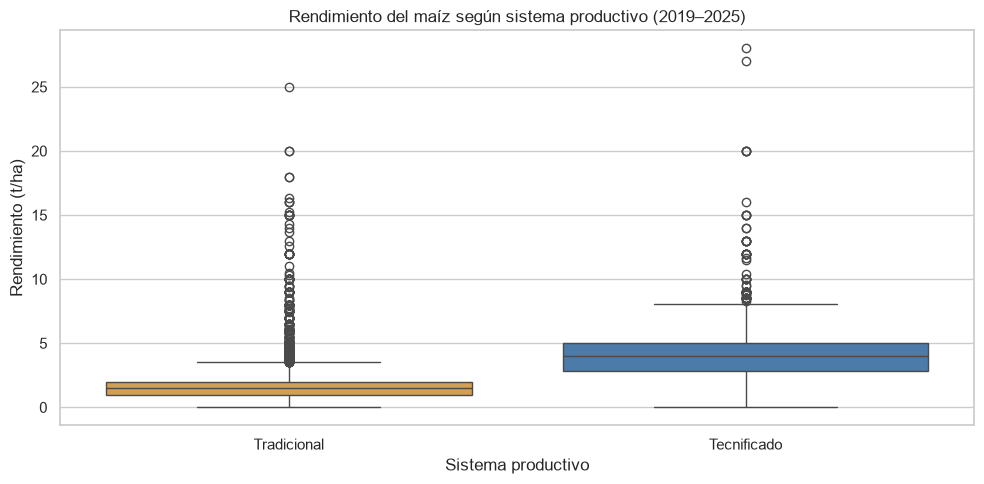

In [17]:
# Clasificar los registros según el sistema productivo
maiz["Sistema productivo"] = np.where(
    maiz["Desagregación cultivo"].str.contains(
        "tecnificado", case=False, na=False
    ),
    "Tecnificado",
    "Tradicional"
)

# Estadísticas descriptivas por sistema
resumen_sistema = (
    maiz.groupby("Sistema productivo")["Rendimiento (t/ha)"]
    .agg(["count", "mean", "median", "std"])
    .round(2)
)

display(resumen_sistema)

# Comparación visual
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=maiz,
    x="Sistema productivo",
    y="Rendimiento (t/ha)",
    order=["Tradicional", "Tecnificado"],
    hue="Sistema productivo",
    palette={"Tradicional": "#E8A33D", "Tecnificado": "#3D7AB8"},
    legend=False
)

plt.title("Rendimiento del maíz según sistema productivo (2019–2025)")
plt.xlabel("Sistema productivo")
plt.ylabel("Rendimiento (t/ha)")
plt.tight_layout()
plt.show()

## 4. Evolución temporal del rendimiento agrícola

Se analiza el comportamiento del rendimiento medio del maíz entre 2019 y 2025, diferenciando los sistemas productivos tradicional y tecnificado.

Los resultados se interpretan como promedios de las observaciones disponibles y no como estimaciones nacionales ponderadas por superficie.

Rendimiento medio por año y sistema:


Sistema productivo,Tecnificado,Tradicional
Año,,
2019,5.15,2.34
2020,4.94,2.32
2021,4.03,1.75
2022,3.75,1.61
2023,3.75,1.57
2024,3.63,1.48
2025,3.83,1.51


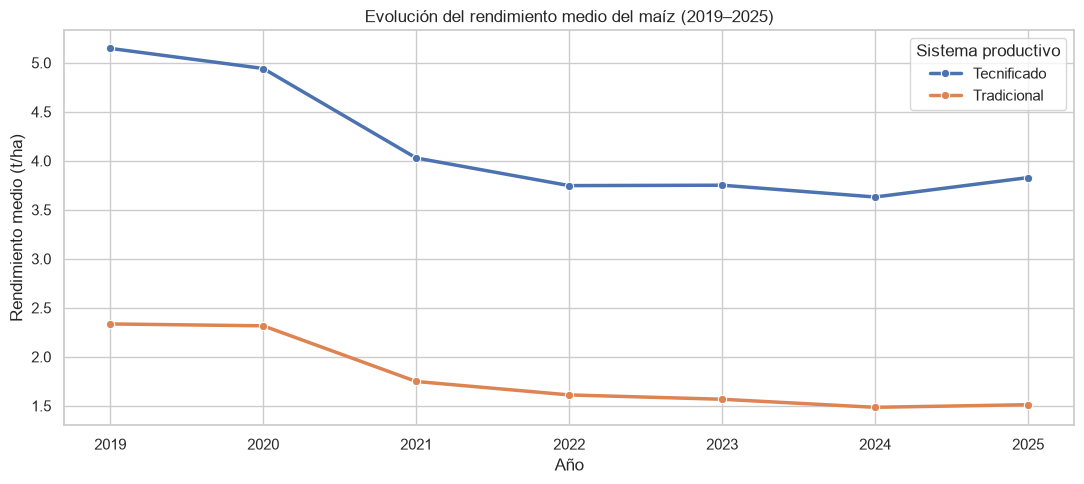

In [21]:
# Rendimiento medio por año y sistema productivo
evolucion = (
    maiz.groupby(["Año", "Sistema productivo"])
    ["Rendimiento (t/ha)"]
    .agg(["mean", "count"])
    .reset_index()
)

print("Rendimiento medio por año y sistema:")
display(
    evolucion.pivot(
        index="Año",
        columns="Sistema productivo",
        values="mean"
    ).round(2)
)

# Gráfico de evolución temporal
plt.figure(figsize=(11, 5))

sns.lineplot(
    data=evolucion,
    x="Año",
    y="mean",
    hue="Sistema productivo",
    marker="o",
    linewidth=2.5
)

plt.title("Evolución del rendimiento medio del maíz (2019–2025)")
plt.xlabel("Año")
plt.ylabel("Rendimiento medio (t/ha)")
plt.xticks(sorted(maiz["Año"].unique()))
plt.legend(title="Sistema productivo")
plt.tight_layout()
plt.show()

## 5. Análisis territorial del rendimiento agrícola

Se examinan las diferencias en el rendimiento del maíz entre departamentos de Colombia. Para la comparación descriptiva se consideran departamentos con al menos 100 registros, evitando interpretar promedios calculados sobre muestras muy pequeñas.

Departamentos representados: 32

Departamentos con mayor rendimiento medio:


,Departamento,registros,rendimiento_medio,municipios
29,Valle del Cauca,1221,3.62,42
20,Meta,715,3.57,29
28,Tolima,1103,3.14,44
17,Huila,1553,2.92,37
25,Risaralda,238,2.70,14
14,Córdoba,890,2.68,29
24,Quindío,241,2.47,12
11,Cesar,762,2.39,25
9,Casanare,439,2.38,19
22,Norte de Santander,746,2.16,39


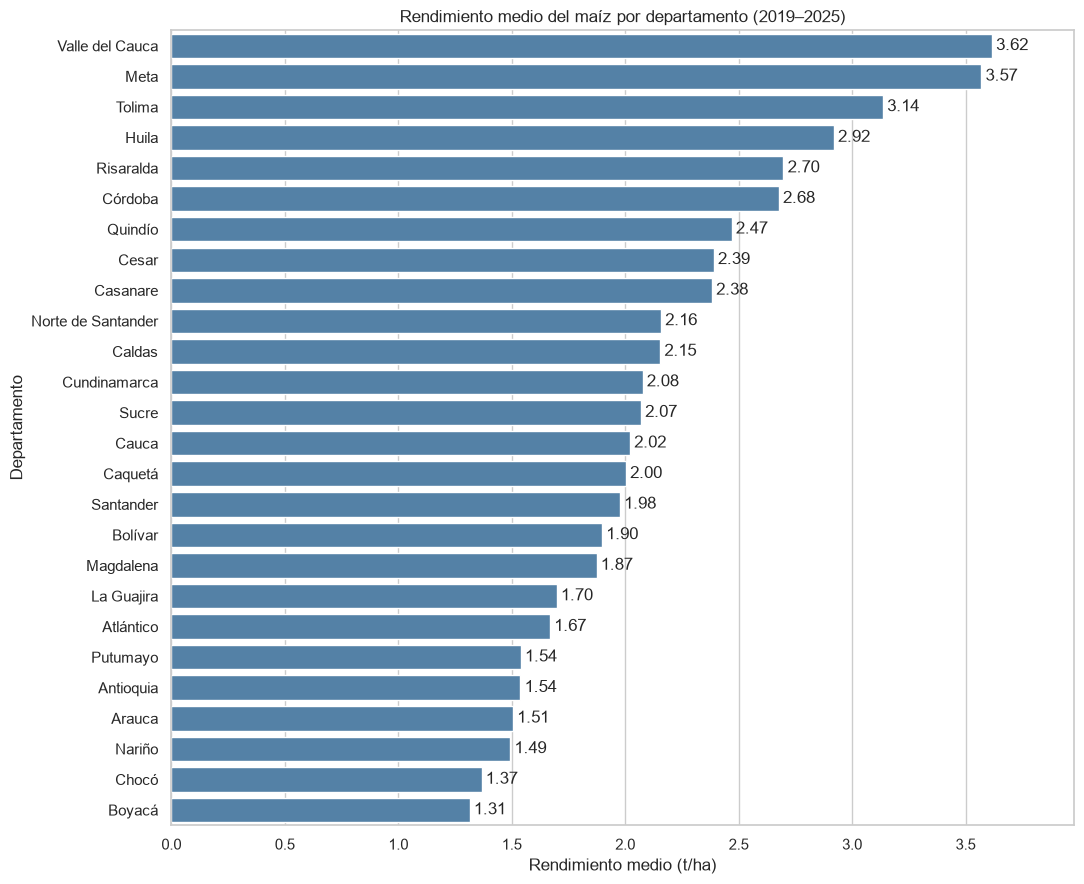

In [18]:
# Resumen departamental
resumen_departamentos = (
    maiz.groupby("Departamento")
    .agg(
        registros=("Rendimiento (t/ha)", "size"),
        rendimiento_medio=("Rendimiento (t/ha)", "mean"),
        municipios=("Código Dane municipio", "nunique")
    )
    .reset_index()
)

# Departamentos con al menos 100 registros
departamentos_grafico = (
    resumen_departamentos[
        resumen_departamentos["registros"] >= 100
    ]
    .sort_values("rendimiento_medio", ascending=False)
)

print("Departamentos representados:",
      resumen_departamentos.shape[0])

print("\nDepartamentos con mayor rendimiento medio:")
display(departamentos_grafico.head(10).round(2))

# Visualización
plt.figure(figsize=(11, 9))

ax= sns.barplot(
    data=departamentos_grafico,
    x="rendimiento_medio",
    y="Departamento",
    color="steelblue"
)
ax.bar_label(ax.containers[0], fmt="%.2f", padding=3)
ax.set_xlim(0, departamentos_grafico["rendimiento_medio"].max() * 1.1)

plt.title("Rendimiento medio del maíz por departamento (2019–2025)")
plt.xlabel("Rendimiento medio (t/ha)")
plt.ylabel("Departamento")
plt.tight_layout()
plt.show()

## 6. Evaluación de calidad y consistencia de los datos

Se analiza la frecuencia de registros en los que el área cosechada supera el área sembrada, considerando los cambios metodológicos de reporte documentados por la UPRA.

,Año,registros,casos,Porcentaje
0,2019,2107,0,0.00
1,2020,2180,0,0.00
2,2021,3526,0,0.00
3,2022,3624,1056,29.14
4,2023,3546,1067,30.09
5,2024,3510,1051,29.94
6,2025,3499,1083,30.95


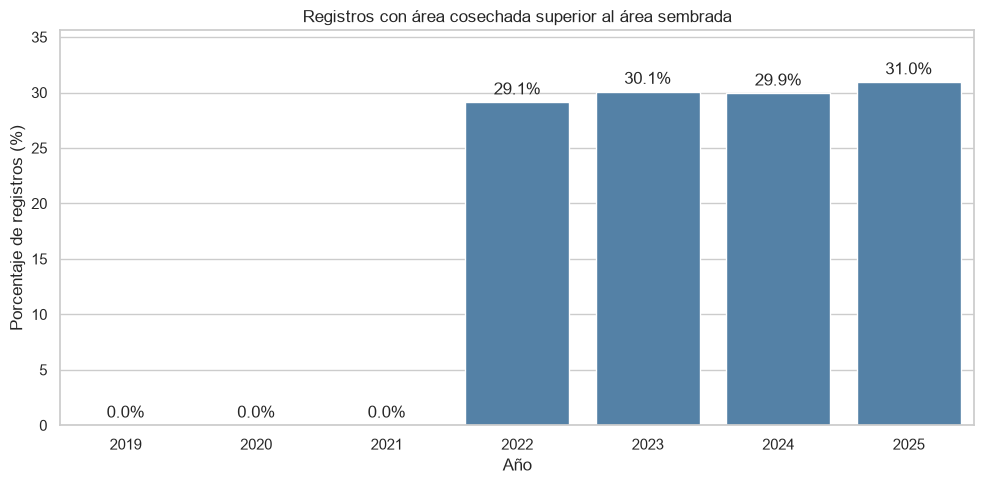

In [19]:
# Identificar registros con área cosechada mayor que sembrada
maiz["Area_cosechada_mayor"] = (
    maiz["Área cosechada (ha)"] >
    maiz["Área sembrada (ha)"]
)

# Resumen anual
calidad_anual = (
    maiz.groupby("Año")
    .agg(
        registros=("Area_cosechada_mayor", "size"),
        casos=("Area_cosechada_mayor", "sum")
    )
    .reset_index()
)

calidad_anual["Porcentaje"] = (
    calidad_anual["casos"] /
    calidad_anual["registros"] * 100
)

display(calidad_anual.round(2))

# Visualización
plt.figure(figsize=(10, 5))

ax=sns.barplot(
    data=calidad_anual,
    x="Año",
    y="Porcentaje",
    color="steelblue"
)
ax.set_ylim(0, calidad_anual["Porcentaje"].max() * 1.15)
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)


plt.title("Registros con área cosechada superior al área sembrada")
plt.xlabel("Año")
plt.ylabel("Porcentaje de registros (%)")
plt.tight_layout()
plt.show()

## 7. Conclusiones preliminares

El análisis exploratorio identificó diferencias importantes en el rendimiento del maíz según el sistema productivo, el año y la ubicación territorial.

El rendimiento presenta una distribución asimétrica, con valores extremos que requieren revisión. El sistema tecnificado registra rendimientos medios superiores al tradicional, mientras que la evolución temporal muestra cambios que deben interpretarse considerando las variaciones de cobertura y metodología de la fuente.

La información disponible permite avanzar hacia la preparación de los datos y el desarrollo de un modelo predictivo, teniendo en cuenta el tratamiento de rendimientos nulos, las diferencias metodológicas entre periodos y la prevención de fuga de información.

In [23]:
from pathlib import Path

carpeta = Path("../docs/figuras")
carpeta.mkdir(parents=True, exist_ok=True)

colores_sistema = {"Tradicional": "#E8A33D", "Tecnificado": "#3D7AB8"}

def guardar(fig, nombre):
    fig.tight_layout()
    fig.savefig(carpeta / nombre, dpi=300)
    plt.close(fig)

# 1. Distribución del rendimiento
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.histplot(data=maiz, x="Rendimiento (t/ha)", bins=50, color="steelblue", ax=ax)
ax.axvline(maiz["Rendimiento (t/ha)"].mean(), color="red", linestyle="--", label="Media")
ax.axvline(maiz["Rendimiento (t/ha)"].median(), color="green", linestyle="--", label="Mediana")
ax.set(title="Distribución del rendimiento del maíz",
       xlabel="Rendimiento (t/ha)", ylabel="Registros")
ax.legend()
guardar(fig, "01_distribucion_rendimiento.png")

# 2. Sistemas productivos
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.boxplot(data=maiz, x="Sistema productivo", y="Rendimiento (t/ha)",
            order=["Tradicional", "Tecnificado"], hue="Sistema productivo",
            palette=colores_sistema, legend=False, ax=ax)
ax.set(title="Rendimiento según sistema productivo",
       xlabel="Sistema productivo", ylabel="Rendimiento (t/ha)")
guardar(fig, "02_sistemas_productivos.png")

# 3. Evolución temporal
evolucion = (
    maiz.groupby(["Año", "Sistema productivo"])["Rendimiento (t/ha)"]
    .agg(["mean"])
    .reset_index()
)
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.lineplot(data=evolucion, x="Año", y="mean", hue="Sistema productivo",
             palette=colores_sistema, marker="o", ax=ax)
ax.set(title="Evolución del rendimiento medio (2019–2025)",
       xlabel="Año", ylabel="Rendimiento medio (t/ha)")
ax.set_xticks(sorted(maiz["Año"].unique()))
ax.legend(title="Sistema productivo")
guardar(fig, "03_evolucion_temporal.png")

# 4. Departamentos
fig, ax = plt.subplots(figsize=(11, 9))
sns.barplot(data=departamentos_grafico, x="rendimiento_medio", y="Departamento",
            color="steelblue", ax=ax)
ax.bar_label(ax.containers[0], fmt="%.2f", padding=3)
ax.set_xlim(0, departamentos_grafico["rendimiento_medio"].max() * 1.1)
ax.set(title="Rendimiento medio del maíz por departamento (2019–2025)",
       xlabel="Rendimiento medio (t/ha)", ylabel="Departamento")
guardar(fig, "04_rendimiento_departamentos.png")

# 5. Calidad: área cosechada > sembrada
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=calidad_anual, x="Año", y="Porcentaje", color="steelblue", ax=ax)
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)
ax.set_ylim(0, calidad_anual["Porcentaje"].max() * 1.15)
ax.set(title="Registros con área cosechada superior al área sembrada",
       xlabel="Año", ylabel="Porcentaje de registros (%)")
guardar(fig, "05_calidad_area_cosechada.png")

print("Gráficas exportadas correctamente:")
for archivo in sorted(carpeta.glob("*.png")):
    print("-", archivo.name)

Gráficas exportadas correctamente:
- 01_distribucion_rendimiento.png
- 02_sistemas_productivos.png
- 03_evolucion_temporal.png
- 04_rendimiento_departamentos.png
- 05_calidad_area_cosechada.png
